# 04 — Compare saved PPO models and benchmarks

Select saved PPO models, SPY buy-and-hold, and an equal-weight sector portfolio in `MODELS_TO_COMPARE`. Model selection is independent of the active training configuration; this notebook does not load checkpoints or retrain models.

The PPO checkpoints were selected using development validation, so these results are for model development rather than final performance claims. The final two-year holdout remains untouched.


In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


## Select models and load saved validation results

Use `SPY` and `equal_weight` in the same list as the saved model names. Remove an entry to exclude it from the comparison.

Saved models load `validation_results.csv` and `validation_metrics.csv` directly from their model folder or from `seed_42/`. Run this notebook from the project root and choose models with the same validation dates. Both benchmarks use the validation dates saved in `models/long_only/validation_results.csv`.


In [2]:
MODELS_TO_COMPARE = [
    'long_only', 'long_short', 'long_short_scaled', 'SPY', 'equal_weight'
]
SAVE_COMPARISON = False
TRADING_DAYS_PER_YEAR = 252

TRADABLE_SYMBOLS = [
    "XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"
]
REBALANCE_INTERVAL_DAYS = 5
TRANSACTION_COST_RATE = 0.0005

# Support running from the project folder or the notebooks folder.
PROJECT_ROOT = Path(".") if Path("notebooks").is_dir() else Path("..")
MODELS_DIRECTORY = PROJECT_ROOT / "models"
FEATURE_PATH = PROJECT_ROOT / "data/processed/market_features.csv.gz"
VALIDATION_DATES_PATH = MODELS_DIRECTORY / "long_only/validation_results.csv"
RESULTS_DIRECTORY = PROJECT_ROOT / "results"


In [3]:
model_results = {}
model_metrics = {}

for model_name in MODELS_TO_COMPARE:
    if model_name in ["SPY", "equal_weight"]:
        continue

    model_directory = MODELS_DIRECTORY / model_name
    if not (model_directory / "validation_results.csv").exists():
        model_directory = model_directory / "seed_42"

    model_results[model_name] = (
        pd.read_csv(model_directory / "validation_results.csv", parse_dates=["date"])
        .set_index("date")
        .sort_index()
    )
    model_metrics[model_name] = pd.read_csv(
        model_directory / "validation_metrics.csv", index_col=0
    )["value"]
    print(f"{model_name}: {model_directory.relative_to(PROJECT_ROOT)}")


long_only: models/long_only
long_short: models/long_short
long_short_scaled: models/long_short_scaled/seed_42


## Build the selected benchmarks

`SPY` is buy-and-hold with no ongoing trading costs.

`equal_weight` starts with equal weights in the nine sector ETFs. Weights drift with daily returns and reset every five trading days. Each rebalance costs 0.05% of turnover, measured as the sum of absolute weight changes. Initial allocation is treated as already invested, with no entry cost, matching the SPY convention.


In [4]:
def run_spy_benchmark(returns):
    """Represent buy-and-hold SPY over the comparison period."""
    return pd.DataFrame(
        {
            "net_return": returns,
            "turnover": 0.0,
            "transaction_cost": 0.0,
            "short_borrow_cost": 0.0,
            "gross_exposure": 1.0,
            "short_exposure": 0.0,
        },
        index=returns.index,
    )


def run_equal_weight_benchmark(returns):
    """Rebalance sector ETFs to equal weights every five trading days."""
    equal_weights = np.full(returns.shape[1], 1 / returns.shape[1])
    weights = equal_weights.copy()
    records = []

    for day, (date, daily_returns) in enumerate(returns.iterrows()):
        turnover = 0.0
        if day > 0 and day % REBALANCE_INTERVAL_DAYS == 0:
            turnover = np.abs(equal_weights - weights).sum()
            weights = equal_weights.copy()

        asset_returns = daily_returns.to_numpy()
        gross_return = float(weights @ asset_returns)
        transaction_cost = TRANSACTION_COST_RATE * turnover
        records.append({
            "date": date,
            "net_return": gross_return - transaction_cost,
            "turnover": turnover,
            "transaction_cost": transaction_cost,
            "short_borrow_cost": 0.0,
            "gross_exposure": 1.0,
            "short_exposure": 0.0,
        })
        weights = weights * (1 + asset_returns) / (1 + gross_return)

    return pd.DataFrame(records).set_index("date")


In [5]:
if "SPY" in MODELS_TO_COMPARE or "equal_weight" in MODELS_TO_COMPARE:
    validation_dates = pd.read_csv(
        VALIDATION_DATES_PATH, usecols=["date"], parse_dates=["date"]
    )["date"]
    market_returns = (
        pd.read_csv(
            FEATURE_PATH,
            usecols=["date", "symbol", "return_1d"],
            parse_dates=["date"],
        )
        .pivot(index="date", columns="symbol", values="return_1d")
        .loc[validation_dates]
    )

strategy_results = {}
for model_name in MODELS_TO_COMPARE:
    if model_name == "SPY":
        strategy_results[model_name] = run_spy_benchmark(market_returns["SPY"])
    elif model_name == "equal_weight":
        strategy_results[model_name] = run_equal_weight_benchmark(
            market_returns[TRADABLE_SYMBOLS]
        )
    else:
        strategy_results[model_name] = model_results[model_name]

validation_dates = next(iter(strategy_results.values())).index
print(
    f"Comparison period: {validation_dates.min().date()} through "
    f"{validation_dates.max().date()} ({len(validation_dates)} days)"
)


Comparison period: 2019-08-27 through 2024-09-30 (1282 days)


## Compare validation performance

Use each PPO model's saved validation metrics and calculate the same metrics for the selected benchmarks. Returns are after trading and borrowing costs. Sharpe uses a zero risk-free rate.


In [6]:
def calculate_metrics(results):
    """Calculate performance and implementation metrics from daily data."""
    returns = results["net_return"]
    cumulative_return = (1 + returns).prod() - 1
    annualized_return = (
        (1 + cumulative_return) ** (TRADING_DAYS_PER_YEAR / len(returns)) - 1
    )
    volatility = returns.std()
    annualized_volatility = volatility * np.sqrt(TRADING_DAYS_PER_YEAR)
    wealth = (1 + returns).cumprod()
    drawdown = wealth / wealth.cummax().clip(lower=1.0) - 1
    return pd.Series(
        {
            "cumulative net return": cumulative_return,
            "annualized net return": annualized_return,
            "annualized volatility": annualized_volatility,
            "Sharpe ratio": (
                returns.mean() / volatility * np.sqrt(TRADING_DAYS_PER_YEAR)
            ),
            "maximum drawdown": drawdown.min(),
            "annualized turnover": results["turnover"].mean() * TRADING_DAYS_PER_YEAR,
            "average gross exposure": results["gross_exposure"].mean(),
            "maximum gross exposure": results["gross_exposure"].max(),
            "average short exposure": results["short_exposure"].mean(),
            "annualized implementation cost": (
                (results["transaction_cost"] + results["short_borrow_cost"]).mean()
                * TRADING_DAYS_PER_YEAR
            ),
        }
    )


comparison_metrics = dict(model_metrics)
for benchmark in ["SPY", "equal_weight"]:
    if benchmark in strategy_results:
        comparison_metrics[benchmark] = calculate_metrics(strategy_results[benchmark])

comparison_table = pd.DataFrame(comparison_metrics).T.loc[MODELS_TO_COMPARE]
display(comparison_table.style.format("{:.3f}"))


,cumulative net return,annualized net return,annualized volatility,Sharpe ratio,maximum drawdown,annualized turnover,average gross exposure,maximum gross exposure,average short exposure,annualized implementation cost
long_only,1.927,0.235,0.248,0.975,-0.351,22.545,1.000,1.000,0.000,0.011
long_short,1.461,0.194,0.215,0.932,-0.331,45.736,1.600,1.647,0.300,0.026
long_short_scaled,1.747,0.220,0.244,0.936,-0.347,16.687,1.584,1.646,0.292,0.011
SPY,1.162,0.164,0.207,0.835,-0.337,0.000,1.000,1.000,0.000,0.000
equal_weight,1.029,0.149,0.204,0.785,-0.369,0.720,1.000,1.000,0.000,0.000


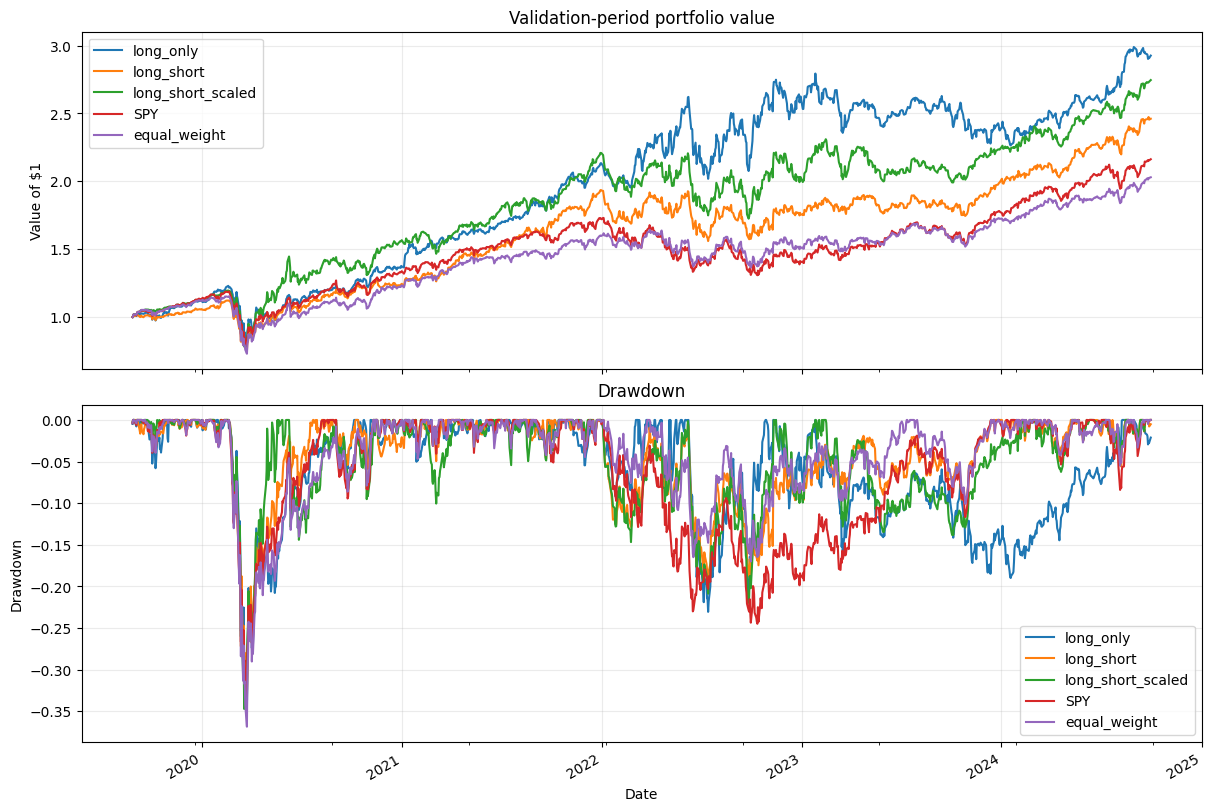

In [7]:
wealth = pd.DataFrame(
    {
        strategy: (1 + results["net_return"]).cumprod()
        for strategy, results in strategy_results.items()
    }
)
drawdowns = wealth / wealth.cummax().clip(lower=1.0) - 1

figure, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True, constrained_layout=True
)
wealth.plot(ax=axes[0])
axes[0].set_title("Validation-period portfolio value")
axes[0].set_ylabel("Value of $1")

drawdowns.plot(ax=axes[1])
axes[1].set_title("Drawdown")
axes[1].set_ylabel("Drawdown")
axes[1].set_xlabel("Date")

for axis in axes:
    axis.grid(alpha=0.25)

plt.show()


## PPO portfolio weights by model

Plot each model's saved `weight_` columns. Negative weights indicate short positions.


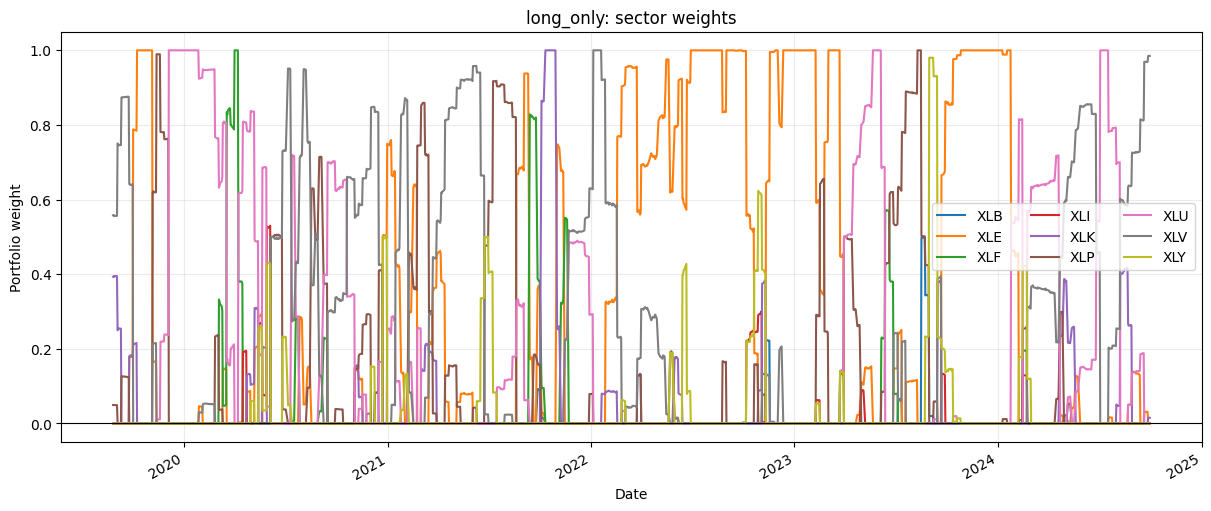

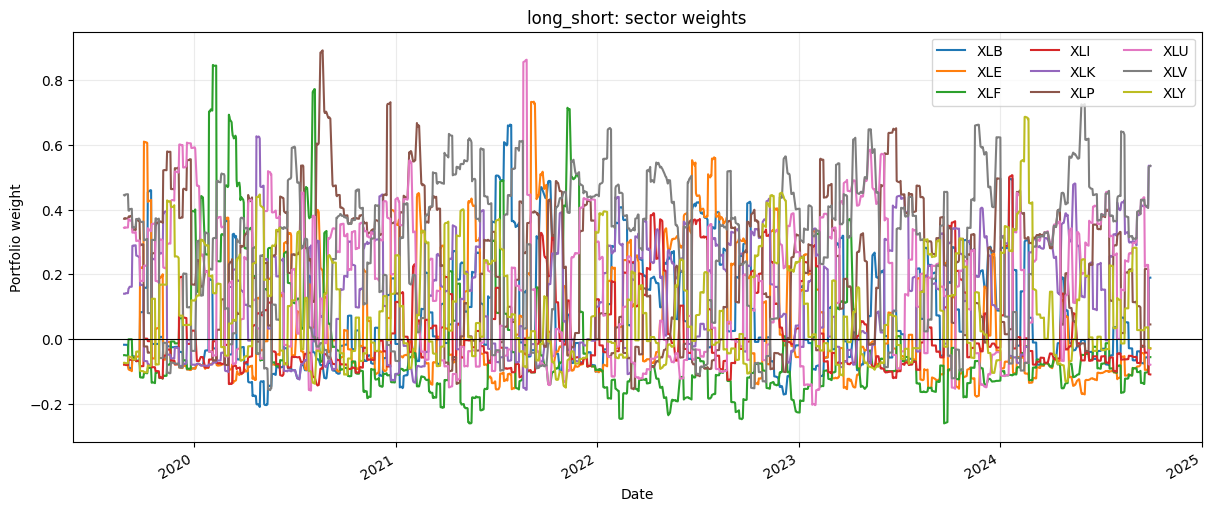

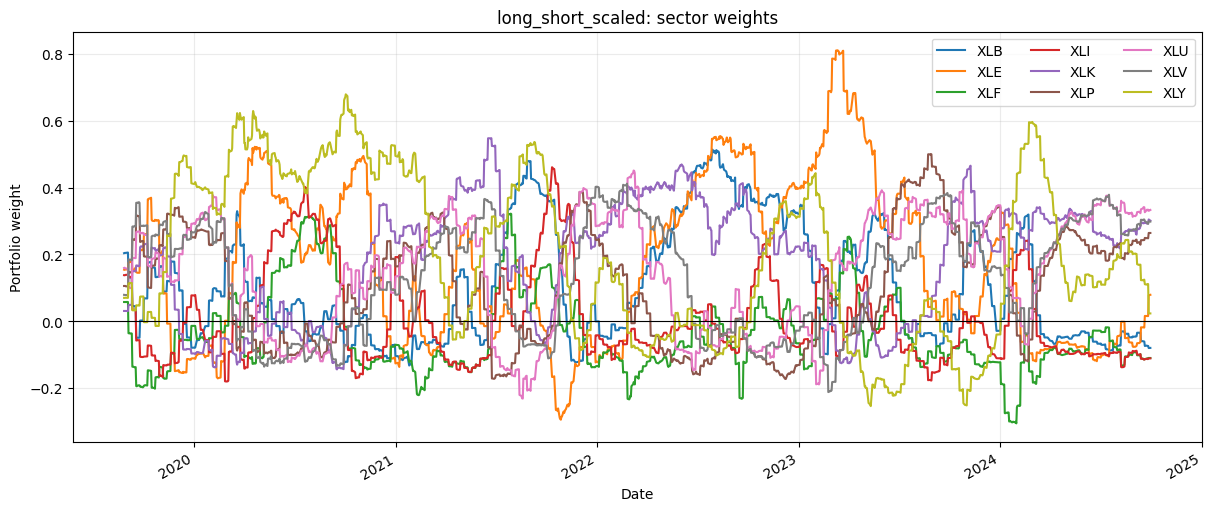

In [8]:
for model_name, results in model_results.items():
    weight_columns = [column for column in results.columns if column.startswith("weight_")]
    figure, axis = plt.subplots(figsize=(12, 5), constrained_layout=True)
    results[weight_columns].rename(
        columns={column: column.removeprefix("weight_") for column in weight_columns}
    ).plot(ax=axis)
    axis.axhline(0, color="black", linewidth=0.8)
    axis.set_title(f"{model_name}: sector weights")
    axis.set_ylabel("Portfolio weight")
    axis.set_xlabel("Date")
    axis.legend(ncol=3)
    axis.grid(alpha=0.25)
    plt.show()


## Calendar-year returns

First and last calendar years may cover only part of a year.


In [9]:
calendar_year_returns = (
    pd.concat(
        {
            strategy: results["net_return"]
            for strategy, results in strategy_results.items()
        },
        axis=1,
    )
    .groupby(lambda date: date.year)
    .apply(lambda returns: (1 + returns).prod() - 1)
)
calendar_year_returns.index.name = "year"
display(calendar_year_returns.style.format("{:.1%}"))

,long_only,long_short,long_short_scaled,SPY,equal_weight
year,,,,,
2019,12.0%,5.5%,12.4%,12.8%,11.9%
2020,22.3%,17.7%,39.2%,18.3%,10.1%
2021,55.6%,55.5%,41.1%,28.7%,29.7%
2022,23.2%,-9.1%,-8.0%,-18.2%,-5.3%
2023,-9.6%,13.4%,10.0%,26.2%,13.9%
2024,23.3%,23.6%,23.0%,21.9%,17.9%
